# ACME Inc. — Performance & Talent Insights

This notebook answers ACME's seven workforce questions from the **Gold layer** of the data lake.
Every number and every finding below is computed live from Gold; nothing is typed in by hand.

| # | Business question | Gold table |
|---|---|---|
| 1 | Performance ratings and review history per employee | `employee_performance_history` |
| 2 | Employees with critical skill gaps | `employee_skill_gaps` |
| 3 | High-potential employees ready for promotion | `promotion_pipeline` |
| 4 | Training and development completed per employee | `employee_course_progress`, `employee_learning_summary` |
| 5 | Employees at risk of attrition, based on performance trends | `attrition_risk` |
| 6 | Performance vs. team and project outcomes | `team_performance_outcomes` |
| 7 | Distribution of skills across the organization | `skill_distribution` |
| 8 | *Beyond the brief:* are talent labels and training aligned with reality? | all of the above |

**How the data got here:** PostgreSQL (HR system) and S3 (learning platform) → **Bronze** (raw, immutable)
→ **Silver** (validated, cleaned, bad records quarantined) → **Gold** (one table per question).

In [1]:
import json
import os

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import pyarrow.fs as pafs
from IPython.display import Markdown, display

# Same environment variables as the pipeline (local: LocalStack, cloud: AWS S3).
IS_LOCAL = os.environ.get("IS_LOCAL", "true").lower() == "true"
BUCKET = os.environ.get("DATALAKE_BUCKET") or f"coding-workshop-datalake-{os.environ.get('PARTICIPANT_ID', 'abcd1234')}"
ENDPOINT = os.environ.get("AWS_ENDPOINT_URL_S3") or ("http://s3.localhost.localstack.cloud:4566" if IS_LOCAL else None)
REGION = os.environ.get("AWS_REGION", "us-east-1")

fs_args = {"region": REGION}
if ENDPOINT:
    fs_args.update(endpoint_override=ENDPOINT, scheme="http" if ENDPOINT.startswith("http://") else "https")
fs = pafs.S3FileSystem(**fs_args)


def read(prefix: str) -> pd.DataFrame:
    """Read a Parquet dataset from the data lake."""
    return ds.dataset(f"{BUCKET}/{prefix}", filesystem=fs, format="parquet", partitioning="hive").to_table().to_pandas()


def gold(table: str) -> pd.DataFrame:
    return read(f"gold/{table}")


def read_json(key: str) -> dict:
    with fs.open_input_stream(f"{BUCKET}/{key}") as f:
        return json.loads(f.read())


history = gold("employee_performance_history")
gaps = gold("employee_skill_gaps")
pipeline = gold("promotion_pipeline")
progress = gold("employee_course_progress")
summary = gold("employee_learning_summary")
risk = gold("attrition_risk")
teams = gold("team_performance_outcomes")
skills = gold("skill_distribution")
report = read_json("_meta/dq_reports/latest/report.json")
latest = history[history["is_latest_review"]]
print(f"Data lake: s3://{BUCKET}  ({'local' if IS_LOCAL else 'cloud'})  |  pipeline run {report['run_id']}")

Data lake: s3://coding-workshop-datalake-abcd1234  (local)  |  pipeline run 20261015T060505Z-07035b


In [2]:
# ---- One visual language for every chart -------------------------------------------------
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch, Rectangle

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"           # categorical slots 1-3 (validated, CVD-safe)
BLUE_LIGHT = "#9ec5f4"
GOOD, WARN, CRIT = "#0ca30c", "#fab219", "#d03b3b"             # status colours, always shown with a label
INK, INK2, MUTED, GRID, BASE, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
CATEGORY = {"Technical": BLUE, "Leadership": ORANGE, "Domain": AQUA}
SEQ = LinearSegmentedColormap.from_list("seq", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASE, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11.5,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "text.color": INK, "font.size": 10, "figure.dpi": 110, "legend.frameon": False, "legend.fontsize": 9,
})


def headline(fig, title, subtitle=""):
    """The finding as the figure title, with a one-line subtitle under it."""
    fig.text(0.0, 1.075, title, ha="left", va="bottom", fontsize=15, fontweight="bold", color=INK)
    if subtitle:
        fig.text(0.0, 1.035, subtitle, ha="left", va="bottom", fontsize=10.5, color=INK2)


def label_bars(ax, container, fmt="{:,.0f}", **kw):
    kw = {"padding": 3, "fontsize": 9, "color": INK2, **kw}
    ax.bar_label(container, labels=[fmt.format(v) for v in container.datavalues], **kw)


def clean_axis(ax, grid_axis="x"):
    ax.grid(axis="y" if grid_axis == "x" else "x", visible=False)


def annotate_heatmap(ax, values, fmt="{:,.0f}", threshold=None, fontsize=10):
    threshold = np.nanmax(values) * 0.55 if threshold is None else threshold
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            v = values[i, j]
            if np.isnan(v):
                continue
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fontsize, color="white" if v > threshold else INK)


def finding(text):
    display(Markdown(f"> **Finding —** {text}"))

## At a glance

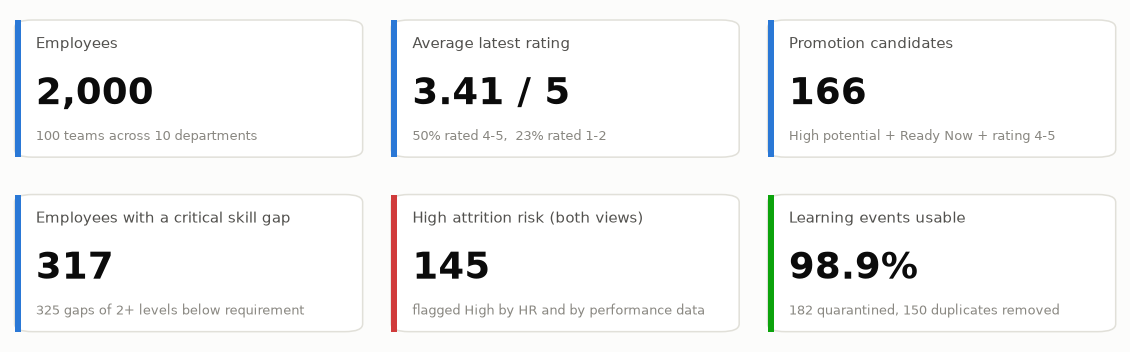

In [3]:
both_high = int(((risk["derived_risk_level"] == "High") & (risk["hr_attrition_risk"] == "High")).sum())
ev = report["entities"]["learning_events"]
tiles = [
    ("Employees", f"{pipeline['employee_id'].nunique():,}", f"{teams['team_id'].nunique()} teams across {teams['department'].nunique()} departments", BLUE),
    ("Average latest rating", f"{latest['rating'].mean():.2f} / 5", f"{(latest['rating'] >= 4).mean():.0%} rated 4-5,  {(latest['rating'] <= 2).mean():.0%} rated 1-2", BLUE),
    ("Promotion candidates", f"{int(pipeline['is_promotion_candidate'].sum()):,}", "High potential + Ready Now + rating 4-5", BLUE),
    ("Employees with a critical skill gap", f"{gaps.loc[gaps['is_critical_gap'], 'employee_id'].nunique():,}", f"{int(gaps['is_critical_gap'].sum())} gaps of 2+ levels below requirement", BLUE),
    ("High attrition risk (both views)", f"{both_high:,}", "flagged High by HR and by performance data", CRIT),
    ("Learning events usable", f"{ev['silver_rows'] / ev['bronze_rows']:.1%}", f"{ev['quarantined_rows']} quarantined, {ev['duplicates_dropped']} duplicates removed", GOOD),
]
fig, axes = plt.subplots(2, 3, figsize=(13, 3.9))
for ax, (label, value, sub, colour) in zip(axes.flat, tiles):
    ax.axis("off")
    ax.add_patch(FancyBboxPatch((0.01, 0.06), 0.98, 0.88, boxstyle="round,pad=0,rounding_size=0.05",
                                transform=ax.transAxes, facecolor="white", edgecolor=GRID, linewidth=1))
    ax.add_patch(Rectangle((0.01, 0.06), 0.018, 0.88, transform=ax.transAxes, facecolor=colour, edgecolor="none"))
    ax.text(0.07, 0.76, label, transform=ax.transAxes, fontsize=10, color=INK2)
    ax.text(0.07, 0.40, value, transform=ax.transAxes, fontsize=24, fontweight="bold", color=INK)
    ax.text(0.07, 0.17, sub, transform=ax.transAxes, fontsize=8.8, color=MUTED)
plt.subplots_adjust(wspace=0.06, hspace=0.12)
plt.show()

## 0. Can these numbers be trusted?

Before any answer: did every record arrive, and what was rejected? The pipeline reconciles every
layer on every run (`raw = clean + quarantined + duplicates`) and writes a data quality report to `_meta/`.

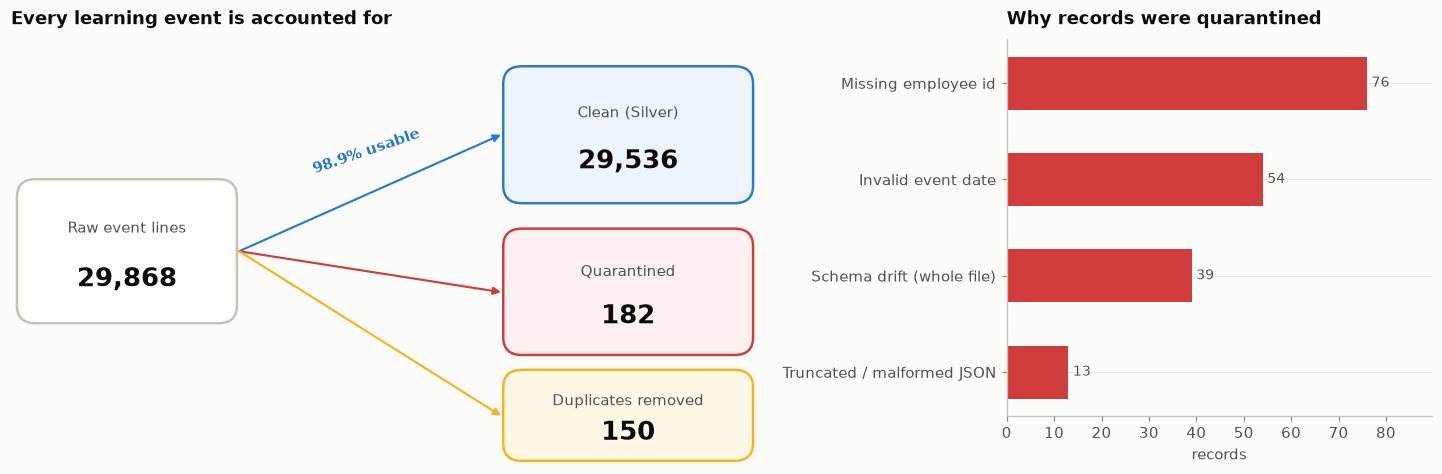

> **Finding —** all 8 entities reconcile. The HR tables were clean; the learning feed had 182 bad records (including one file whose schema drifted, quarantined whole) and 150 duplicates. None of them reach the analysis below.

,raw (Bronze),clean (Silver),quarantined,duplicates,reconciles
entity,,,,,
teams,100,100,0,0,yes
competencies,40,40,0,0,yes
employees,2000,2000,0,0,yes
projects,33,33,0,0,yes
performance_reviews,4000,4000,0,0,yes
competency_assessments,4000,4000,0,0,yes
talent_review,2000,2000,0,0,yes
learning_events,29868,29536,182,150,yes


In [4]:
READABLE = {"employee_id": "Missing employee id", "event_date": "Invalid event date",
            "file quarantined for schema drift": "Schema drift (whole file)", "malformed JSON": "Truncated / malformed JSON"}
reasons = (pd.Series(ev["rejection_reasons"]).rename(lambda r: READABLE.get(r.split(":")[0], r.split(":")[0]))
           .groupby(level=0).sum().sort_values())

fig = plt.figure(figsize=(13, 4.2), layout="constrained")
left, right = fig.subfigures(1, 2, width_ratios=[1.15, 1])
ax = left.subplots()
ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 6)
def node(x, y, w, h, title, value, colour, fill="white"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.25", facecolor=fill, edgecolor=colour, linewidth=1.6))
    ax.text(x + w / 2, y + h * 0.66, title, ha="center", va="center", fontsize=10, color=INK2)
    ax.text(x + w / 2, y + h * 0.30, value, ha="center", va="center", fontsize=17, fontweight="bold", color=INK)
node(0.1, 2.0, 2.9, 2.0, "Raw event lines", f"{ev['bronze_rows']:,}", BASE)
node(6.6, 3.7, 3.3, 1.9, "Clean (Silver)", f"{ev['silver_rows']:,}", BLUE, "#eef4fc")
node(6.6, 1.55, 3.3, 1.75, "Quarantined", f"{ev['quarantined_rows']:,}", CRIT, "#fdf0f0")
node(6.6, 0.05, 3.3, 1.25, "Duplicates removed", f"{ev['duplicates_dropped']:,}", WARN, "#fff8e6")
for y_end, colour in [(4.65, BLUE), (2.42, CRIT), (0.67, WARN)]:
    ax.annotate("", xy=(6.55, y_end), xytext=(3.05, 3.0), arrowprops=dict(arrowstyle="-|>", color=colour, lw=1.4, shrinkA=0, shrinkB=0, connectionstyle="arc3,rad=0"))
ax.text(4.75, 4.05, f"{ev['silver_rows'] / ev['bronze_rows']:.1%} usable", ha="center", va="bottom", rotation=19, fontsize=10, color=BLUE, fontweight="bold")
ax.set_title("Every learning event is accounted for", loc="left")

ax2 = right.subplots()
bars = ax2.barh(reasons.index, reasons.values, color=CRIT, height=0.55)
label_bars(ax2, bars); clean_axis(ax2, "y")
ax2.set_title("Why records were quarantined"); ax2.set_xlabel("records"); ax2.set_xlim(0, reasons.max() * 1.18)
plt.show()

health = pd.DataFrame([
    {"entity": e, "raw (Bronze)": s["bronze_rows"], "clean (Silver)": s["silver_rows"], "quarantined": s["quarantined_rows"],
     "duplicates": s["duplicates_dropped"], "reconciles": "yes" if report["reconciliation"][e] else "NO"}
    for e, s in report["entities"].items() if "bronze_rows" in s]).set_index("entity")
finding(f"all {len(health)} entities reconcile. The HR tables were clean; the learning feed had {ev['quarantined_rows']} bad records "
        f"(including one file whose schema drifted, quarantined whole) and {ev['duplicates_dropped']} duplicates. None of them reach the analysis below.")
health

## 1. Performance ratings and review history

Every employee has two reviews (2024-H2 and 2025-H1). Left: how the rating mix shifted. Middle: where each
employee moved, row = previous rating, column = latest. Right: how departments compare.

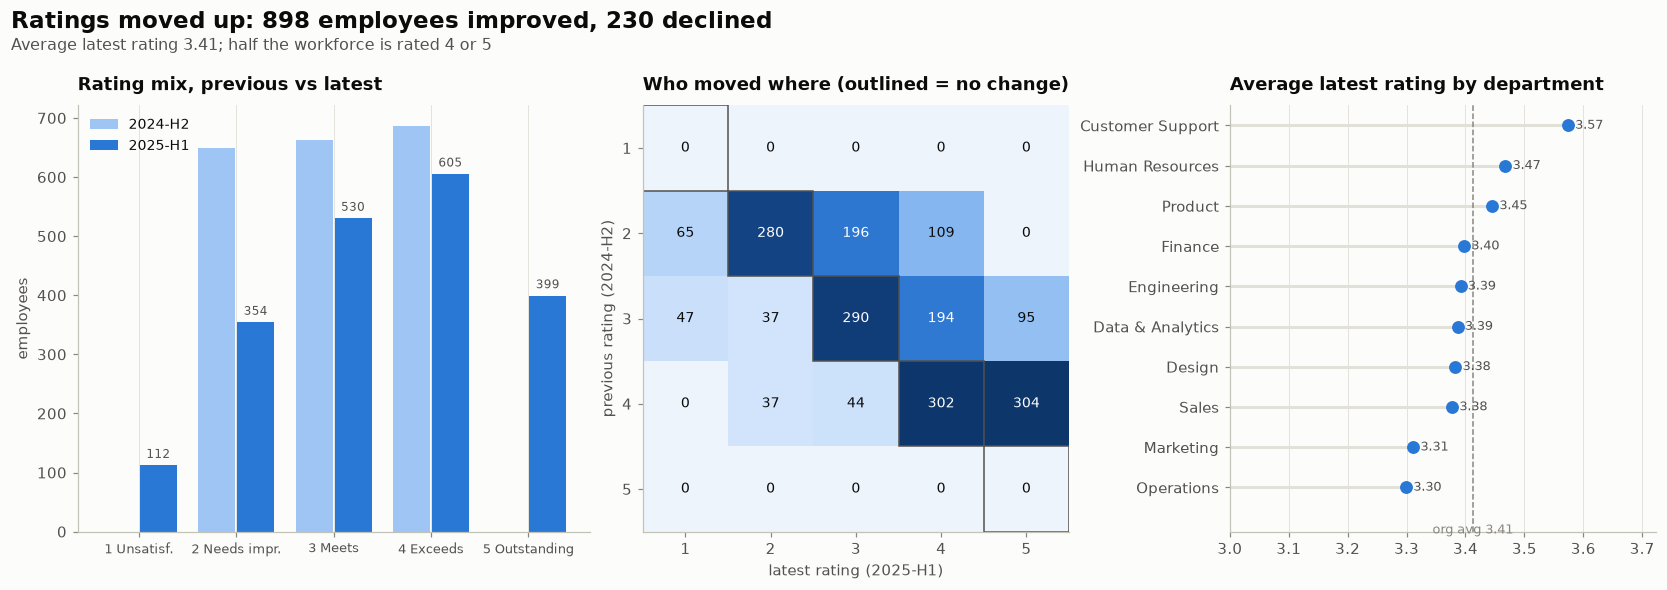

> **Finding —** 872 employees (44%) kept the same rating, 898 improved and 230 declined. Departments sit within 0.27 points of each other, from Operations (3.30) to Customer Support (3.57).

In [5]:
prev = history[history["review_period"] == "2024-H2"].set_index("employee_id")["rating"]
curr = history[history["review_period"] == "2025-H1"].set_index("employee_id")["rating"]
moves = pd.crosstab(prev, curr).reindex(index=range(1, 6), columns=range(1, 6), fill_value=0)
labels = ["1 Unsatisf.", "2 Needs impr.", "3 Meets", "4 Exceeds", "5 Outstanding"]
dept = latest.groupby("department")["rating"].mean().sort_values()
org = latest["rating"].mean()
improved, declined = int((curr > prev).sum()), int((curr < prev).sum())

fig, (a, b, c) = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.2, 1, 1]}, layout="constrained")
headline(fig, f"Ratings moved up: {improved:,} employees improved, {declined:,} declined",
         f"Average latest rating {org:.2f}; half the workforce is rated 4 or 5")
x = np.arange(5)
b1 = a.bar(x - 0.2, prev.value_counts().reindex(range(1, 6), fill_value=0), 0.38, color=BLUE_LIGHT, label="2024-H2")
b2 = a.bar(x + 0.2, curr.value_counts().reindex(range(1, 6), fill_value=0), 0.38, color=BLUE, label="2025-H1")
label_bars(a, b2, fontsize=8)
a.set_xticks(x, labels, fontsize=8.5); a.set_ylabel("employees"); a.legend(loc="upper left"); clean_axis(a)
a.set_title("Rating mix, previous vs latest")

b.imshow(moves.values, cmap=SEQ)
annotate_heatmap(b, moves.values.astype(float), fontsize=9)
for k in range(5):
    b.add_patch(Rectangle((k - 0.5, k - 0.5), 1, 1, fill=False, edgecolor=INK2, linewidth=1))
b.set_xticks(range(5), range(1, 6)); b.set_yticks(range(5), range(1, 6)); b.grid(False)
b.set_xlabel("latest rating (2025-H1)"); b.set_ylabel("previous rating (2024-H2)")
b.set_title("Who moved where (outlined = no change)")

c.hlines(range(len(dept)), 3.0, dept.values, color=GRID, linewidth=2)
c.scatter(dept.values, range(len(dept)), color=BLUE, s=55, zorder=3)
for i, v in enumerate(dept.values):
    c.text(v + 0.012, i, f"{v:.2f}", va="center", fontsize=8.5, color=INK2)
c.axvline(org, color=MUTED, linestyle="--", linewidth=1)
c.text(org, -0.9, f"org avg {org:.2f}", ha="center", va="top", fontsize=8.5, color=MUTED)
c.set_ylim(-1.1, len(dept) - 0.5)
c.set_yticks(range(len(dept)), dept.index); c.set_xlim(3.0, dept.max() + 0.15); c.grid(axis="y", visible=False)
c.set_title("Average latest rating by department")
plt.show()

same = int(np.trace(moves.values))
finding(f"{same:,} employees ({same / len(curr):.0%}) kept the same rating, {improved:,} improved and {declined:,} declined. "
        f"Departments sit within {dept.max() - dept.min():.2f} points of each other, from {dept.index[0]} ({dept.iloc[0]:.2f}) to {dept.index[-1]} ({dept.iloc[-1]:.2f}).")

In [6]:
# Review history for any employee: change the id to look someone up.
EMPLOYEE_ID = int(latest.sort_values(["rating_change", "employee_id"]).iloc[0]["employee_id"])
history[history["employee_id"] == EMPLOYEE_ID][["full_name", "department", "job_level", "review_period", "rating", "rating_label", "rating_change", "manager_comment"]]

,full_name,department,job_level,review_period,rating,rating_label,rating_change,manager_comment
14,Mike Gamble,Operations,Senior Manager,2024-H2,3,Meets Expectations,NaN,Delivered on commitments with no major concerns.
15,Mike Gamble,Operations,Senior Manager,2025-H1,1,Unsatisfactory,-2.0,Engagement and output have both trended down.


## 2. Critical skill gaps

A **gap** is `required level − proficiency level` for an assessed skill. A gap of **2 or more levels**
is **critical** (assumption documented in `docs/limitations.md`).

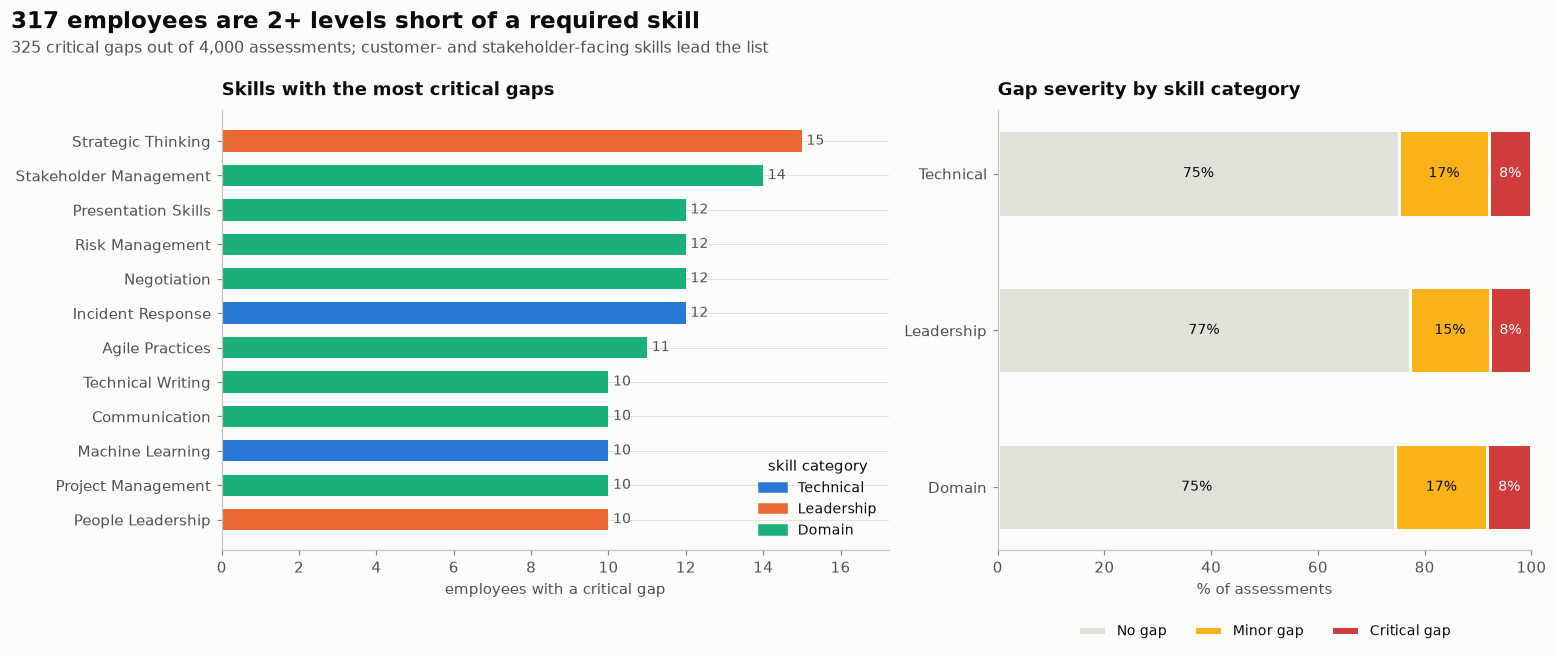

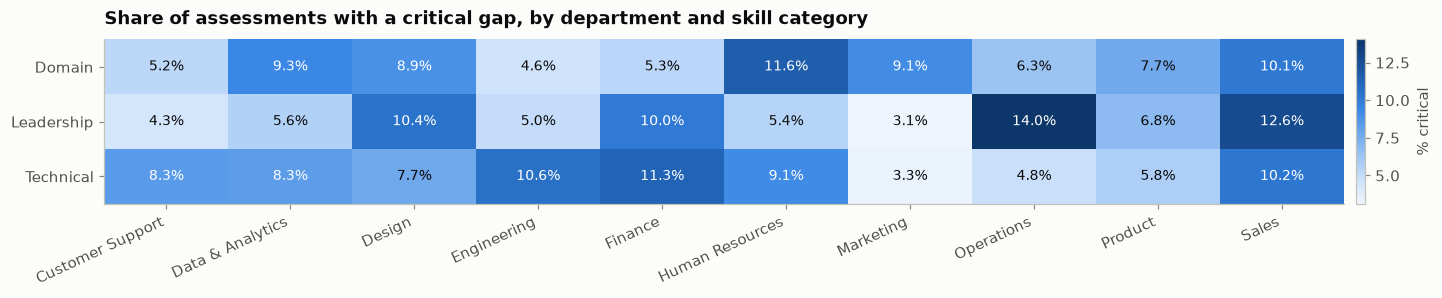

> **Finding —** the highest critical-gap rate is Leadership skills in Operations (14.0% of assessments). The table below lists the people and skills to target first.

In [7]:
critical = gaps[gaps["is_critical_gap"]]
top = critical.groupby(["competency_name", "competency_category"]).size().reset_index(name="n").sort_values("n").tail(12)
sev = (gaps.groupby(["competency_category", "gap_severity"]).size().unstack(fill_value=0)
       .reindex(columns=["No gap", "Minor gap", "Critical gap"], fill_value=0))
sev_pct = sev.div(sev.sum(axis=1), axis=0) * 100
rate = (gaps.groupby(["department", "competency_category"])["is_critical_gap"].mean().unstack() * 100)

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.25, 1]}, layout="constrained")
headline(fig, f"{critical['employee_id'].nunique():,} employees are 2+ levels short of a required skill",
         f"{len(critical):,} critical gaps out of {len(gaps):,} assessments; customer- and stakeholder-facing skills lead the list")
bars = a.barh(top["competency_name"], top["n"], color=[CATEGORY[c] for c in top["competency_category"]], height=0.62)
label_bars(a, bars); clean_axis(a, "y"); a.set_xlim(0, top["n"].max() * 1.15)
a.legend(handles=[Rectangle((0, 0), 1, 1, color=v) for v in CATEGORY.values()], labels=list(CATEGORY), loc="lower right", title="skill category")
a.set_title("Skills with the most critical gaps"); a.set_xlabel("employees with a critical gap")

left_pos = np.zeros(len(sev_pct))
for col, colour in zip(sev_pct.columns, [GRID, WARN, CRIT]):
    b.barh(sev_pct.index, sev_pct[col], left=left_pos, color=colour, height=0.55, label=col, edgecolor=SURFACE, linewidth=2)
    for i, v in enumerate(sev_pct[col]):
        if v >= 6:
            b.text(left_pos[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=9, color=INK if col != "Critical gap" else "white")
    left_pos += sev_pct[col].values
b.set_xlim(0, 100); b.set_xlabel("% of assessments"); clean_axis(b, "y")
b.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)
b.set_title("Gap severity by skill category")
plt.show()

fig, ax = plt.subplots(figsize=(13, 2.6), layout="constrained")
im = ax.imshow(rate.T.values, cmap=SEQ, aspect="auto")
annotate_heatmap(ax, rate.T.values, fmt="{:.1f}%", fontsize=9)
ax.set_xticks(range(len(rate.index)), rate.index, rotation=25, ha="right"); ax.set_yticks(range(3), rate.columns); ax.grid(False)
ax.set_title("Share of assessments with a critical gap, by department and skill category")
fig.colorbar(im, ax=ax, fraction=0.015, pad=0.01, label="% critical")
plt.show()
worst = rate.stack().sort_values().index[-1]
finding(f"the highest critical-gap rate is {worst[1]} skills in {worst[0]} ({rate.loc[worst]:.1f}% of assessments). "
        f"The table below lists the people and skills to target first.")

In [8]:
critical.sort_values(["gap", "employee_id"], ascending=[False, True])[
    ["employee_id", "full_name", "department", "job_level", "competency_name", "competency_category", "proficiency_level", "required_level", "gap"]
].head(15)

,employee_id,full_name,department,job_level,competency_name,competency_category,proficiency_level,required_level,gap
3240,2,Kristie Heath,Sales,Director,Strategic Thinking,Leadership,2,4,2
1132,5,Linda Murray,Sales,IC1,Machine Learning,Technical,1,3,2
2065,11,Natalie Wallace,Sales,Director,Coaching & Mentoring,Leadership,1,3,2
2806,19,Kaylee Reid,Design,Senior Manager,People Leadership,Leadership,1,3,2
1419,31,Douglas Salinas,Design,Director,Data Privacy,Domain,2,4,2
2066,33,Madison Kirby,Design,Director,Security Fundamentals,Technical,1,3,2
476,38,David Gonzalez,Design,Senior Manager,Data Modeling,Technical,1,3,2
2931,40,Lindsey Harris,Design,IC1,People Leadership,Leadership,2,4,2
1198,49,Brandon Weiss,Sales,Senior Manager,Machine Learning,Technical,1,3,2
2217,52,Kelly Smith,Sales,Senior IC,Agile Practices,Domain,2,4,2


## 3. High-potential employees ready for promotion

Left: the industry-standard **9-box grid** (latest performance × potential). Right: how the shortlist narrows.
A **promotion candidate** is *High potential* **and** *Ready Now* **and** rated 4 or 5 in the latest review.

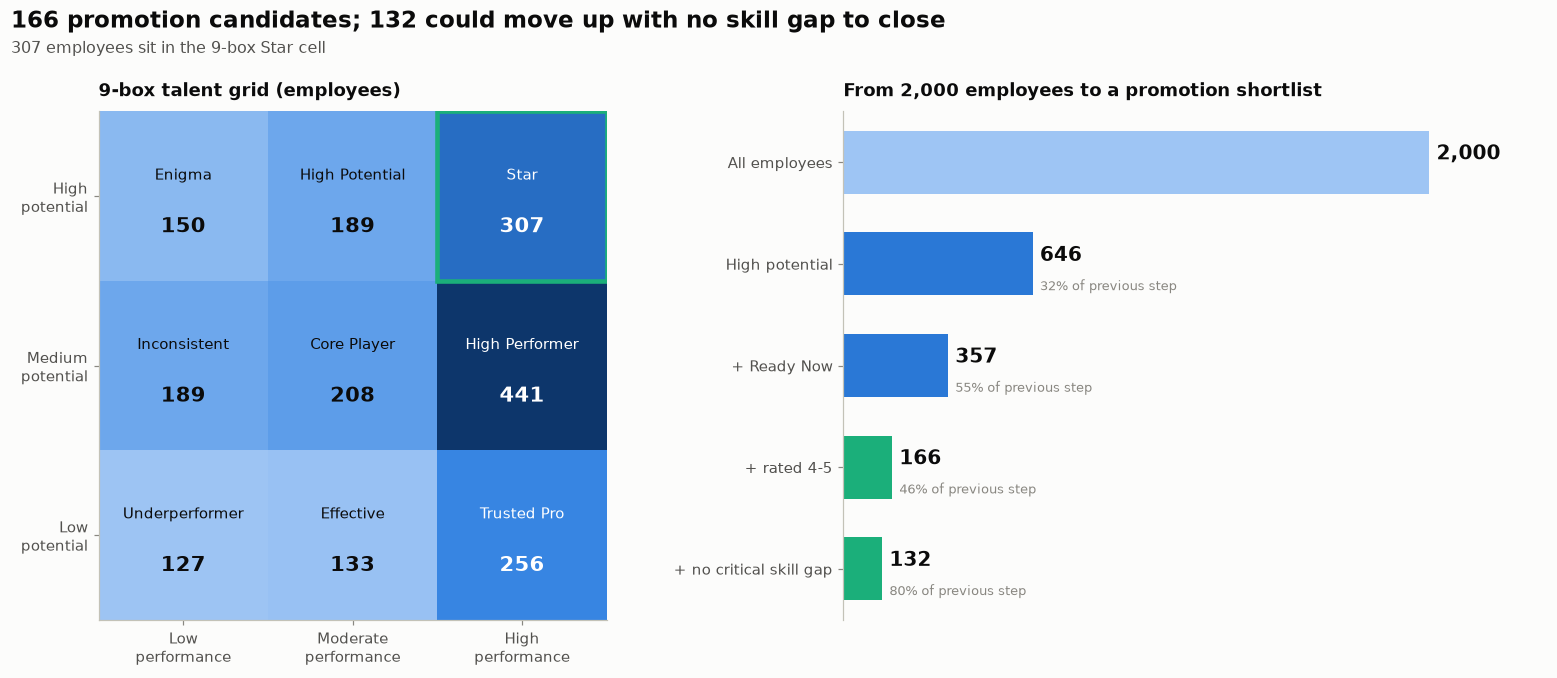

In [9]:
grid = pd.crosstab(pipeline["potential_rating"], pipeline["performance_band"]).reindex(index=["High", "Medium", "Low"], columns=["Low", "Moderate", "High"])
names = {("High", "Low"): "Enigma", ("High", "Moderate"): "High Potential", ("High", "High"): "Star",
         ("Medium", "Low"): "Inconsistent", ("Medium", "Moderate"): "Core Player", ("Medium", "High"): "High Performer",
         ("Low", "Low"): "Underperformer", ("Low", "Moderate"): "Effective", ("Low", "High"): "Trusted Pro"}
hp = pipeline["is_high_potential"]; rn = pipeline["is_ready_now"]; top_rated = pipeline["latest_rating"] >= 4
no_gap = pipeline["critical_gap_count"] == 0
steps = [("All employees", len(pipeline)), ("High potential", int(hp.sum())), ("+ Ready Now", int((hp & rn).sum())),
         ("+ rated 4-5", int((hp & rn & top_rated).sum())), ("+ no critical skill gap", int((hp & rn & top_rated & no_gap).sum()))]

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1, 1.15]}, layout="constrained")
headline(fig, f"{steps[3][1]} promotion candidates; {steps[4][1]} could move up with no skill gap to close",
         f"{grid.loc['High', 'High']} employees sit in the 9-box Star cell")
a.imshow(grid.values, cmap=SEQ, vmin=0)
for i, pot in enumerate(grid.index):
    for j, perf in enumerate(grid.columns):
        v = grid.loc[pot, perf]
        colour = "white" if v > grid.values.max() * 0.55 else INK
        a.text(j, i - 0.12, names[(pot, perf)], ha="center", va="center", fontsize=9.5, color=colour)
        a.text(j, i + 0.18, f"{v:,}", ha="center", va="center", fontsize=14, fontweight="bold", color=colour)
a.add_patch(Rectangle((1.5, -0.5), 1, 1, fill=False, edgecolor=AQUA, linewidth=3))
a.set_xticks(range(3), [f"{c}\nperformance" for c in grid.columns]); a.set_yticks(range(3), [f"{p}\npotential" for p in grid.index])
a.grid(False); a.set_title("9-box talent grid (employees)")

for i, (name, n) in enumerate(steps):
    colour = AQUA if i >= 3 else BLUE_LIGHT if i == 0 else BLUE
    b.barh(i, n, color=colour, height=0.62)
    b.text(n + 25, i - 0.08, f"{n:,}", va="center", fontsize=13, fontweight="bold", color=INK)
    if i:
        b.text(n + 25, i + 0.22, f"{n / steps[i - 1][1]:.0%} of previous step", va="center", fontsize=8.5, color=MUTED)
b.set_yticks(range(len(steps)), [s[0] for s in steps], fontsize=10)
b.set_xlim(0, steps[0][1] * 1.2); b.set_ylim(len(steps) - 0.5, -0.5)
b.grid(False); b.set_xticks([]); b.spines[["bottom"]].set_visible(False)
b.set_title("From 2,000 employees to a promotion shortlist", loc="left")
plt.show()

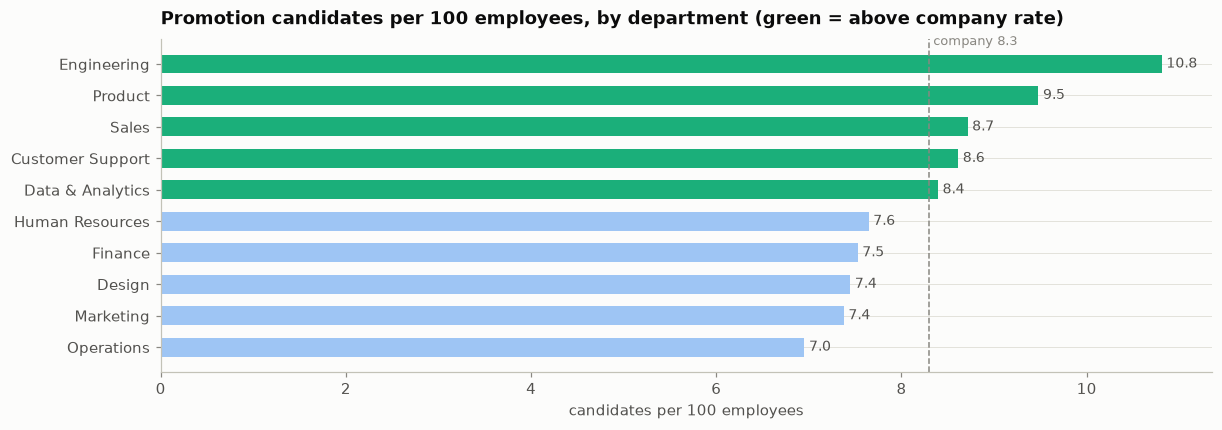

> **Finding —** Engineering has the deepest bench (10.8 candidates per 100 employees); Operations the thinnest (7.0). 34 candidates still carry a critical skill gap and should get a development plan with the promotion.

,employee_id,full_name,department,job_level,latest_rating,nine_box,critical_gap_count,certifications
643,932,Donald Nichols,Product,IC2,5,Star,1,5
996,1527,Sarah Rivera,Sales,Senior Manager,5,Star,0,3
1032,1833,Linda Crawford,Sales,IC2,5,Star,1,3
1214,1484,Melissa Anderson,Design,IC2,5,Star,0,3
1367,701,Yolanda Foley,Marketing,IC2,5,Star,0,3
406,988,Brian Moore,Sales,IC1,5,Star,1,2
700,1346,Thomas Walker,Human Resources,IC2,5,Star,0,2
824,145,Lisa Johnson,Product,Manager,5,Star,0,2
1009,1634,Christine Davis,Design,Director,5,Star,0,2
1082,297,Nicole Boyd,Product,Manager,5,Star,0,2


In [10]:
cand = pipeline[pipeline["is_promotion_candidate"]]
per100 = (cand.groupby("department").size() / pipeline.groupby("department").size() * 100).fillna(0).sort_values()
org_rate = len(cand) / len(pipeline) * 100
fig, ax = plt.subplots(figsize=(11, 3.8), layout="constrained")
bars = ax.barh(per100.index, per100.values, color=[AQUA if v >= org_rate else BLUE_LIGHT for v in per100.values], height=0.6)
label_bars(ax, bars, "{:.1f}"); clean_axis(ax, "y")
ax.axvline(org_rate, color=MUTED, linestyle="--", linewidth=1); ax.text(org_rate, len(per100) - 0.4, f" company {org_rate:.1f}", color=MUTED, fontsize=8.5)
ax.set_title("Promotion candidates per 100 employees, by department (green = above company rate)"); ax.set_xlabel("candidates per 100 employees")
plt.show()
finding(f"{per100.index[-1]} has the deepest bench ({per100.iloc[-1]:.1f} candidates per 100 employees); {per100.index[0]} the thinnest ({per100.iloc[0]:.1f}). "
        f"{int((cand['critical_gap_count'] > 0).sum())} candidates still carry a critical skill gap and should get a development plan with the promotion.")
cand.sort_values(["latest_rating", "certifications"], ascending=False)[
    ["employee_id", "full_name", "department", "job_level", "latest_rating", "nine_box", "critical_gap_count", "certifications"]].head(15)

## 4. Training and development completed

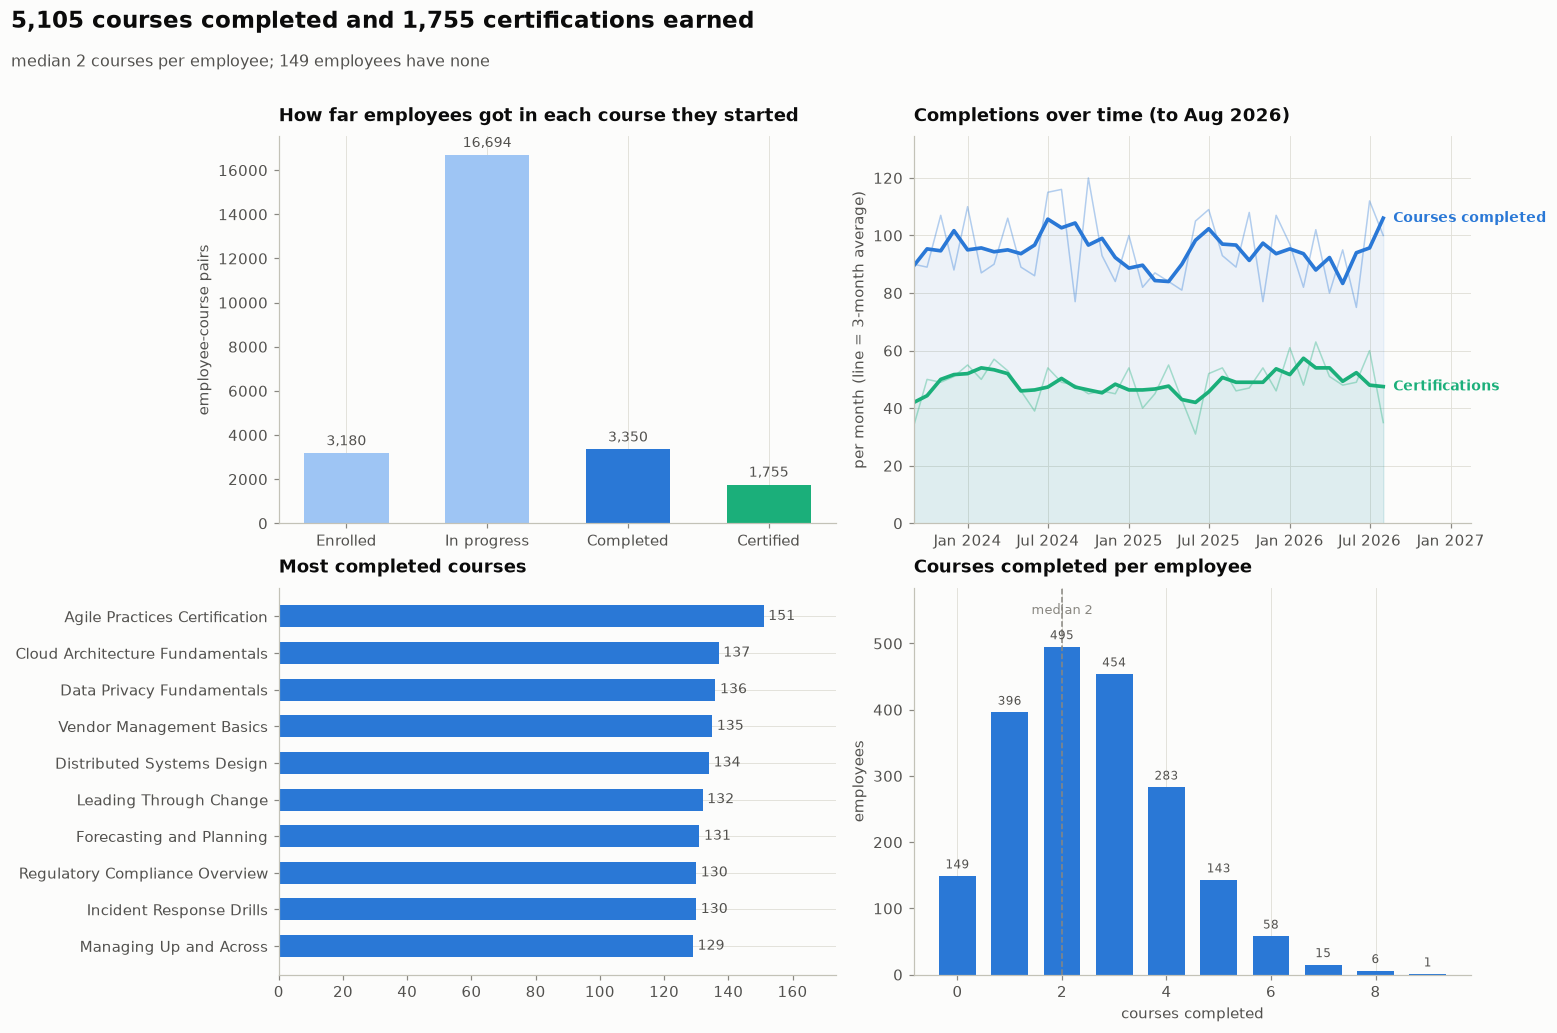

> **Finding —** 5,105 of 24,979 course starts (20%) reached completion. Completions peaked in October 2024; Agile Practices Certification is the most completed course.

In [11]:
status = progress["status"].value_counts().reindex(["Enrolled", "In progress", "Completed", "Certified"])
done = progress.dropna(subset=["completed_on"]).assign(month=lambda d: pd.to_datetime(d["completed_on"]).dt.to_period("M").dt.to_timestamp())
cert = progress.dropna(subset=["certified_on"]).assign(month=lambda d: pd.to_datetime(d["certified_on"]).dt.to_period("M").dt.to_timestamp())
monthly = pd.DataFrame({"Courses completed": done.groupby("month").size(), "Certifications": cert.groupby("month").size()}).fillna(0)
last_day = max(pd.to_datetime(done["completed_on"]).max(), pd.to_datetime(cert["certified_on"]).max())
if last_day.day < 28:  # the data ends early in this month: a partial month would look like a collapse
    monthly = monthly[monthly.index < last_day.to_period("M").to_timestamp()]
top_courses = progress[progress["is_completed"]].groupby("course_name").size().sort_values().tail(10)
per_emp = summary["courses_completed"].value_counts().sort_index()

fig, axes = plt.subplots(2, 2, figsize=(14, 8.4), layout="constrained")
headline(fig, f"{int(summary['courses_completed'].sum()):,} courses completed and {int(summary['certifications'].sum()):,} certifications earned",
         f"median {summary['courses_completed'].median():.0f} courses per employee; {int((summary['courses_completed'] == 0).sum())} employees have none")
a, b, c, d = axes.flat
bars = a.bar(status.index, status.values, color=[BLUE_LIGHT, BLUE_LIGHT, BLUE, AQUA], width=0.6)
label_bars(a, bars); clean_axis(a); a.set_ylabel("employee-course pairs")
a.set_title("How far employees got in each course they started")

for col, colour in [("Courses completed", BLUE), ("Certifications", AQUA)]:
    smooth = monthly[col].rolling(3, center=True, min_periods=1).mean()
    b.plot(monthly.index, monthly[col], color=colour, linewidth=1, alpha=0.35)
    b.plot(monthly.index, smooth, color=colour, linewidth=2.4)
    b.fill_between(monthly.index, 0, smooth, color=colour, alpha=0.07)
    b.text(monthly.index[-1], smooth.iloc[-1], f"  {col}", color=colour, va="center", fontsize=9, fontweight="bold")
b.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); b.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
b.set_ylim(0, monthly.values.max() * 1.12)
b.set_ylabel("per month (line = 3-month average)"); b.set_title(f"Completions over time (to {monthly.index[-1]:%b %Y})")
b.set_xlim(monthly.index[0], monthly.index[-1] + pd.Timedelta(days=200))

bars = c.barh(top_courses.index, top_courses.values, color=BLUE, height=0.6)
label_bars(c, bars); clean_axis(c, "y"); c.set_title("Most completed courses"); c.set_xlim(0, top_courses.max() * 1.15)

bars = d.bar(per_emp.index, per_emp.values, color=BLUE, width=0.7)
label_bars(d, bars, fontsize=8); clean_axis(d)
d.axvline(summary["courses_completed"].median(), color=MUTED, linestyle="--", linewidth=1)
d.text(summary["courses_completed"].median(), per_emp.max() * 1.1, f"median {summary['courses_completed'].median():.0f}", ha="center", color=MUTED, fontsize=8.5)
d.set_ylim(0, per_emp.max() * 1.18)
d.set_xlabel("courses completed"); d.set_ylabel("employees"); d.set_title("Courses completed per employee")
plt.show()
peak = monthly["Courses completed"].idxmax()
finding(f"{status['Certified'] + status['Completed']:,} of {status.sum():,} course starts ({(status['Certified'] + status['Completed']) / status.sum():.0%}) reached completion. "
        f"Completions peaked in {peak:%B %Y}; {top_courses.index[-1]} is the most completed course.")

In [12]:
# Completed training for any employee: change the id.
EMPLOYEE_ID = int(summary.sort_values("courses_completed", ascending=False).iloc[0]["employee_id"])
progress[(progress["employee_id"] == EMPLOYEE_ID) & progress["is_completed"]][
    ["full_name", "course_name", "competency_name", "status", "completed_on", "certified_on", "best_quiz_score"]]

,full_name,course_name,competency_name,status,completed_on,certified_on,best_quiz_score
222,Bryan Ware,Time Management for Professionals,Time Management,Completed,2024-12-09,None,NaN
436,Bryan Ware,Test Automation Bootcamp,Test Automation,Certified,2025-12-18,2026-08-27,20.0
585,Bryan Ware,Resolving Team Conflict,Conflict Resolution,Completed,2024-05-20,None,NaN
604,Bryan Ware,Customer Empathy Workshop,Customer Empathy,Certified,None,2024-07-18,NaN
1176,Bryan Ware,New Hire Onboarding Enablement,Onboarding & Enablement,Completed,2024-12-13,None,NaN
1226,Bryan Ware,Project Management Fundamentals,Project Management,Completed,2023-10-17,None,NaN
1705,Bryan Ware,API Design Best Practices,API Design,Certified,None,2023-10-17,NaN
2948,Bryan Ware,Dimensional Data Modeling,Data Modeling,Completed,2025-08-29,None,NaN
2958,Bryan Ware,Effective Decision Making,Decision Making,Completed,2025-09-05,None,NaN


## 5. Attrition risk based on performance trends

Two views side by side: **HR risk** (the manager-assessed flag) and **derived risk** computed from data signals:
rating declined (+2), latest rating ≤ 2 (+2), negative manager comment (+1), no learning in 180 days (+1); 3+ = High.
With two review periods, a "trend" is one period-over-period change.

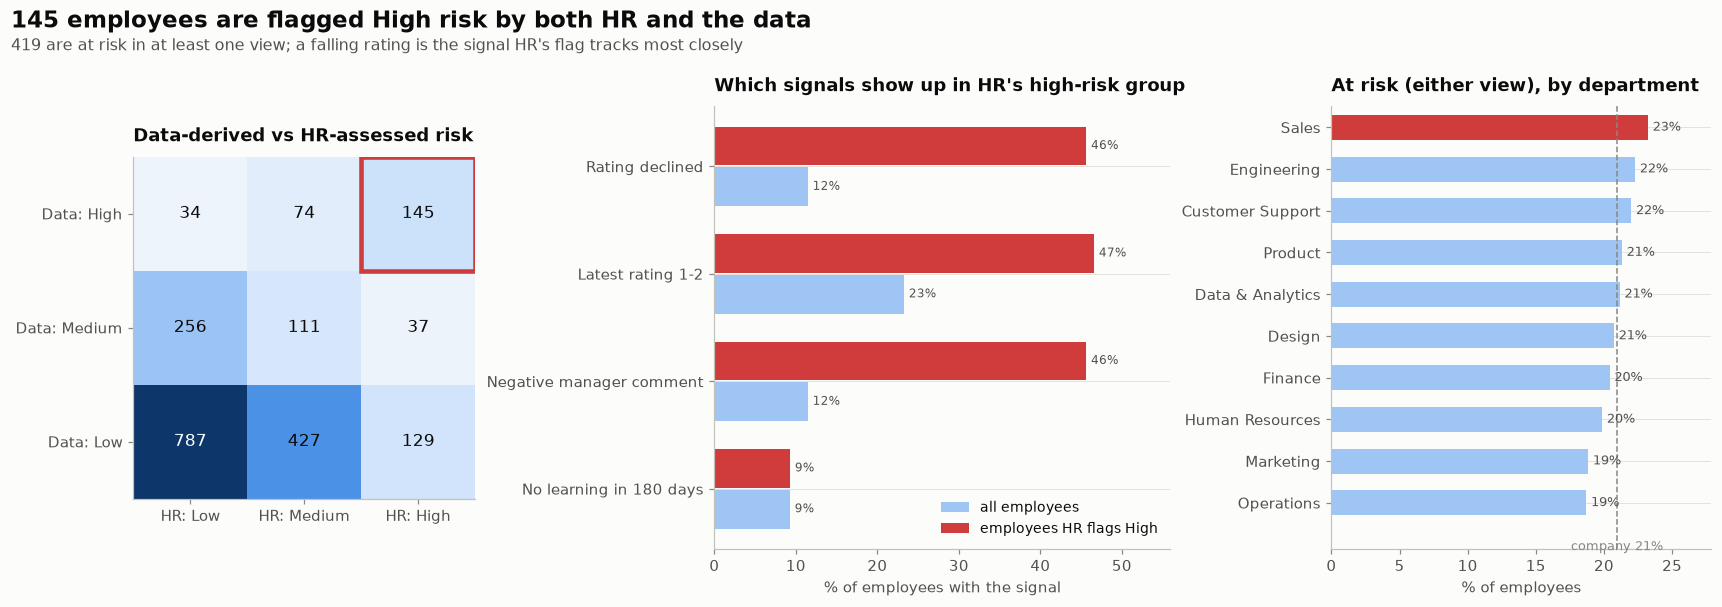

> **Finding —** 46% of employees HR flags High had a falling rating, versus 12% overall. Sales has the highest share at risk (23%, company 21%).

In [13]:
xtab = pd.crosstab(risk["derived_risk_level"], risk["hr_attrition_risk"]).reindex(index=["High", "Medium", "Low"], columns=["Low", "Medium", "High"])
signals = {"Rating declined": "signal_rating_declined", "Latest rating 1-2": "signal_low_rating",
           "Negative manager comment": "signal_negative_comment", "No learning in 180 days": "signal_no_recent_learning"}
sig = pd.DataFrame({"All employees": {k: risk[v].mean() * 100 for k, v in signals.items()},
                    "HR flags High": {k: risk.loc[risk["hr_attrition_risk"] == "High", v].mean() * 100 for k, v in signals.items()}})
by_dept = (risk.groupby("department")["is_at_risk"].mean() * 100).sort_values()

fig, (a, b, c) = plt.subplots(1, 3, figsize=(15.5, 4.8), gridspec_kw={"width_ratios": [0.9, 1.2, 1]}, layout="constrained")
headline(fig, f"{both_high} employees are flagged High risk by both HR and the data",
         f"{int(risk['is_at_risk'].sum())} are at risk in at least one view; a falling rating is the signal HR's flag tracks most closely")
a.imshow(xtab.values, cmap=SEQ)
annotate_heatmap(a, xtab.values.astype(float), fontsize=11)
a.add_patch(Rectangle((1.5, -0.5), 1, 1, fill=False, edgecolor=CRIT, linewidth=3))
a.set_xticks(range(3), [f"HR: {v}" for v in xtab.columns]); a.set_yticks(range(3), [f"Data: {v}" for v in xtab.index]); a.grid(False)
a.set_title("Data-derived vs HR-assessed risk")

y = np.arange(len(sig))
b1 = b.barh(y + 0.19, sig["All employees"], 0.36, color=BLUE_LIGHT, label="all employees")
b2 = b.barh(y - 0.19, sig["HR flags High"], 0.36, color=CRIT, label="employees HR flags High")
label_bars(b, b1, "{:.0f}%", fontsize=8); label_bars(b, b2, "{:.0f}%", fontsize=8)
b.set_yticks(y, sig.index); b.invert_yaxis(); clean_axis(b, "y"); b.set_xlim(0, sig.values.max() * 1.2)
b.legend(loc="lower right"); b.set_xlabel("% of employees with the signal"); b.set_title("Which signals show up in HR's high-risk group")

bars = c.barh(by_dept.index, by_dept.values, color=[CRIT if v == by_dept.max() else BLUE_LIGHT for v in by_dept.values], height=0.6)
label_bars(c, bars, "{:.0f}%", fontsize=8.5); clean_axis(c, "y")
org_risk = risk["is_at_risk"].mean() * 100
c.axvline(org_risk, color=MUTED, linestyle="--", linewidth=1); c.set_xlim(0, by_dept.max() * 1.2)
c.text(org_risk, -0.9, f"company {org_risk:.0f}%", ha="center", va="top", fontsize=8.5, color=MUTED); c.set_ylim(-1.1, len(by_dept) - 0.5)
c.set_title("At risk (either view), by department"); c.set_xlabel("% of employees")
plt.show()
finding(f"{sig.loc['Rating declined', 'HR flags High']:.0f}% of employees HR flags High had a falling rating, versus {sig.loc['Rating declined', 'All employees']:.0f}% overall. "
        f"{by_dept.index[-1]} has the highest share at risk ({by_dept.iloc[-1]:.0f}%, company {org_risk:.0f}%).")

In [14]:
# Retention priority: flagged High by both views, highest data score first.
risk[(risk["derived_risk_level"] == "High") & (risk["hr_attrition_risk"] == "High")].sort_values(["derived_risk_score", "employee_id"], ascending=[False, True])[
    ["employee_id", "full_name", "department", "previous_rating", "latest_rating", "learning_events_last_180d", "derived_risk_score", "latest_manager_comment"]].head(15)

,employee_id,full_name,department,previous_rating,latest_rating,learning_events_last_180d,derived_risk_score,latest_manager_comment
541,111,Brian Brock,Finance,2,1,0,6,Engagement and output have both trended down.
302,243,Robert Brady,Customer Support,3,2,0,6,Struggled to meet deadlines; follow-up plan re...
1567,371,Anne Long,Operations,4,2,0,6,Engagement and output have both trended down.
1853,702,Crystal Logan,Marketing,3,1,0,6,Struggled to meet deadlines; follow-up plan re...
1183,1147,David Mcclure,Human Resources,2,1,0,6,Engagement and output have both trended down.
438,1225,Amy Tucker,Marketing,2,1,0,6,Engagement and output have both trended down.
448,1299,Joseph Ford,Design,2,1,0,6,Struggled to meet deadlines; follow-up plan re...
1709,1550,Rodney Wilkerson,Customer Support,3,2,0,6,Missed several key deliverables this cycle; ne...
1772,8,Sherry Coleman,Sales,3,2,3,5,Missed several key deliverables this cycle; ne...
1527,45,Donna Green,Sales,3,2,2,5,Missed several key deliverables this cycle; ne...


## 6. Performance vs. team and project outcomes

Projects belong to teams, so this is a **team-level** comparison: the average latest rating of each team's members
against its projects' outcomes. Only **27 of 100 teams** have projects (33 projects), so treat it as indicative.

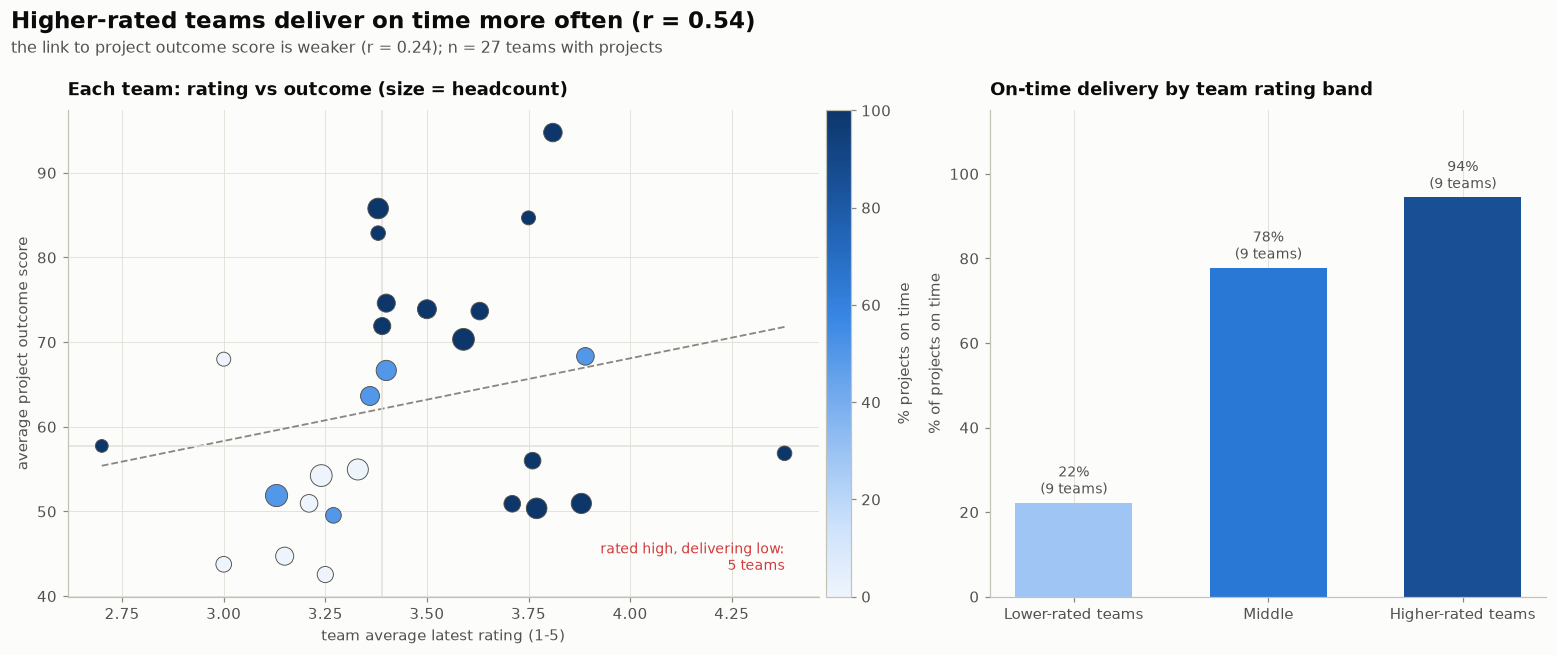

> **Finding —** on-time delivery rises from 22% for the lower-rated third of teams to 94% for the higher-rated third. 5 teams are rated above the median but deliver below-median outcomes, which is worth a calibration conversation. This is a correlation on 27 teams, not proof of cause.

In [15]:
wp = teams[teams["has_projects"]].copy()
r_score = wp["avg_latest_rating"].corr(wp["avg_outcome_score"])
r_ontime = wp["avg_latest_rating"].corr(wp["on_time_rate_pct"])
wp["rating band"] = pd.qcut(wp["avg_latest_rating"], 3, labels=["Lower-rated teams", "Middle", "Higher-rated teams"])
band = wp.groupby("rating band", observed=True).agg(on_time=("on_time_rate_pct", "mean"), score=("avg_outcome_score", "mean"), n=("team_id", "size"))
mx, my = wp["avg_latest_rating"].median(), wp["avg_outcome_score"].median()
mismatch = wp[(wp["avg_latest_rating"] > mx) & (wp["avg_outcome_score"] < my)]

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.35, 1]}, layout="constrained")
headline(fig, f"Higher-rated teams deliver on time more often (r = {r_ontime:.2f})",
         f"the link to project outcome score is weaker (r = {r_score:.2f}); n = {len(wp)} teams with projects")
sc = a.scatter(wp["avg_latest_rating"], wp["avg_outcome_score"], s=wp["headcount"] * 7, c=wp["on_time_rate_pct"], cmap=SEQ,
               vmin=0, vmax=100, edgecolor=INK2, linewidth=0.6, zorder=3)
coef = np.polyfit(wp["avg_latest_rating"], wp["avg_outcome_score"], 1)
xs = np.linspace(wp["avg_latest_rating"].min(), wp["avg_latest_rating"].max(), 50)
a.plot(xs, np.polyval(coef, xs), color=MUTED, linestyle="--", linewidth=1.2)
a.axvline(mx, color=GRID, linewidth=1); a.axhline(my, color=GRID, linewidth=1)
a.text(wp["avg_latest_rating"].max(), wp["avg_outcome_score"].min(), f"rated high, delivering low:\n{len(mismatch)} teams",
       ha="right", va="bottom", fontsize=9, color=CRIT)
fig.colorbar(sc, ax=a, fraction=0.04, pad=0.01, label="% projects on time")
a.set_xlabel("team average latest rating (1-5)"); a.set_ylabel("average project outcome score")
a.set_title("Each team: rating vs outcome (size = headcount)")

x = np.arange(len(band))
bars = b.bar(x, band["on_time"], color=[BLUE_LIGHT, BLUE, "#184f95"], width=0.6)
b.bar_label(bars, labels=[f"{v:.0f}%\n({n} teams)" for v, n in zip(band["on_time"], band["n"])], padding=3, fontsize=9, color=INK2)
b.set_xticks(x, band.index); b.set_ylim(0, 115); b.set_ylabel("% of projects on time"); clean_axis(b)
b.set_title("On-time delivery by team rating band")
plt.show()
finding(f"on-time delivery rises from {band['on_time'].iloc[0]:.0f}% for the lower-rated third of teams to {band['on_time'].iloc[-1]:.0f}% for the higher-rated third. "
        f"{len(mismatch)} teams are rated above the median but deliver below-median outcomes, which is worth a calibration conversation. This is a correlation on {len(wp)} teams, not proof of cause.")

## 7. Distribution of skills across the organization

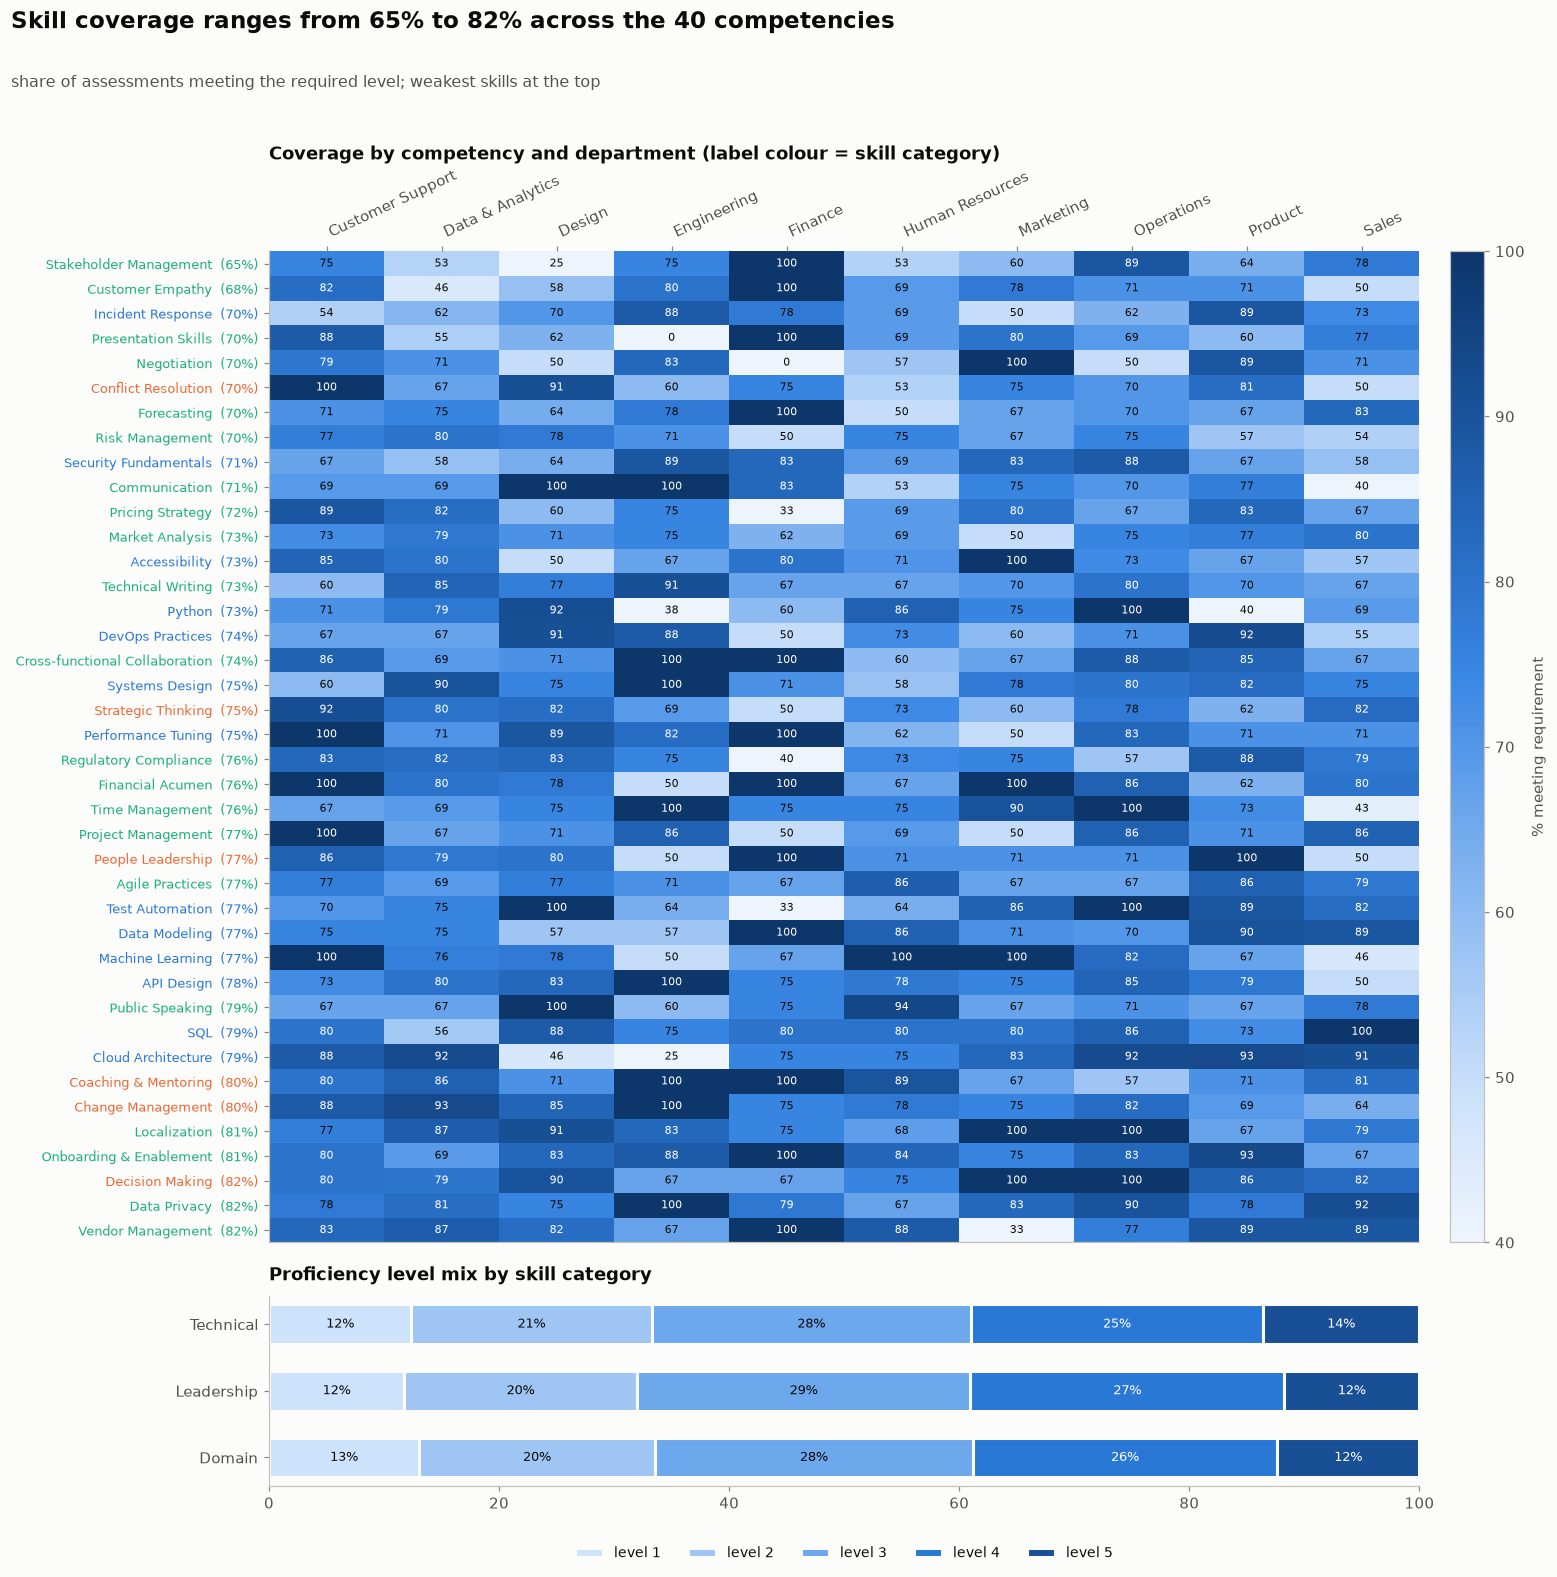

> **Finding —** weakest org-wide: Stakeholder Management, Customer Empathy, Incident Response. Strongest: Vendor Management, Data Privacy, Decision Making. Customer- and stakeholder-facing skills are where training budget would close the most gaps.

In [16]:
cov = skills.assign(met=skills["pct_meeting_requirement"] * skills["assessments"] / 100)
by_comp = cov.groupby(["competency_name", "competency_category"])[["met", "assessments"]].sum()
by_comp["pct"] = by_comp["met"] / by_comp["assessments"] * 100
order = by_comp.sort_values("pct").index.get_level_values(0)
heat = (cov.groupby(["competency_name", "department"])[["met", "assessments"]].sum()
        .assign(pct=lambda d: d["met"] / d["assessments"] * 100)["pct"].unstack().reindex(order))
levels = skills.groupby("competency_category")[[f"level_{n}_count" for n in range(1, 6)]].sum()
levels_pct = levels.div(levels.sum(axis=1), axis=0) * 100

fig = plt.figure(figsize=(14, 13), layout="constrained")
headline(fig, f"Skill coverage ranges from {by_comp['pct'].min():.0f}% to {by_comp['pct'].max():.0f}% across the 40 competencies",
         "share of assessments meeting the required level; weakest skills at the top")
gs = fig.add_gridspec(2, 2, height_ratios=[5.2, 1], width_ratios=[1, 0.03])
ax = fig.add_subplot(gs[0, 0]); cax = fig.add_subplot(gs[0, 1])
im = ax.imshow(heat.values, cmap=SEQ, aspect="auto", vmin=40, vmax=100)
annotate_heatmap(ax, heat.values, fmt="{:.0f}", threshold=78, fontsize=7.5)
ax.set_yticks(range(len(heat)), [f"{n}  ({by_comp.loc[n, 'pct'].iloc[0]:.0f}%)" for n in heat.index], fontsize=8.5)
for t, name in zip(ax.get_yticklabels(), heat.index):
    t.set_color(CATEGORY[by_comp.loc[name].index[0]])
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=25, ha="right"); ax.grid(False); ax.xaxis.tick_top()
plt.setp(ax.get_xticklabels(), rotation=25, ha="left")
fig.colorbar(im, cax=cax, label="% meeting requirement")
ax.set_title("Coverage by competency and department (label colour = skill category)", pad=60)

ax2 = fig.add_subplot(gs[1, 0])
left_pos = np.zeros(3)
for k, colour in zip(range(1, 6), ["#cde2fb", "#9ec5f4", "#6da7ec", "#2a78d6", "#184f95"]):
    vals = levels_pct[f"level_{k}_count"].values
    ax2.barh(levels_pct.index, vals, left=left_pos, color=colour, edgecolor=SURFACE, linewidth=2, height=0.6, label=f"level {k}")
    for i, v in enumerate(vals):
        ax2.text(left_pos[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8.5, color="white" if k >= 4 else INK)
    left_pos += vals
ax2.set_xlim(0, 100); clean_axis(ax2, "y"); ax2.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.25))
ax2.set_title("Proficiency level mix by skill category")
plt.show()
finding(f"weakest org-wide: {', '.join(order[:3])}. Strongest: {', '.join(order[-3:][::-1])}. "
        "Customer- and stakeholder-facing skills are where training budget would close the most gaps.")

## 8. Beyond the brief: are talent labels and training aligned with reality?

Two checks that go past the seven questions, using the same Gold tables:
1. Do the talent review labels (potential, promotion readiness) match how people actually perform?
2. Is training reaching the critical skill gaps?

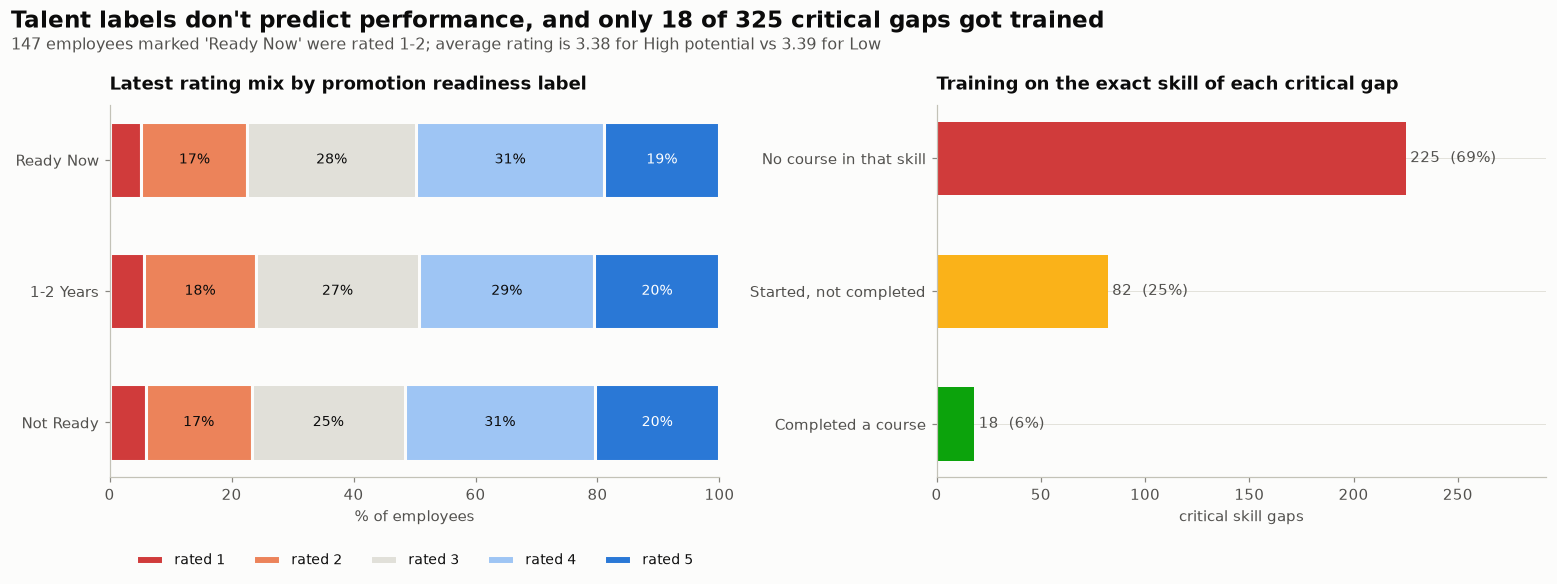

> **Finding —** the rating mix is almost identical whether someone is labelled Ready Now or Not Ready, and 147 'Ready Now' employees were rated 1-2: the talent review needs recalibrating against performance data. Separately, 225 of 325 critical gaps (69%) have no training in that skill at all, so learning budget is not reaching the gaps.

In [17]:
mix = (pipeline.groupby(["promotion_readiness", "latest_rating"]).size().unstack(fill_value=0)
       .reindex(index=["Ready Now", "1-2 Years", "Not Ready"], columns=range(1, 6), fill_value=0))
mix_pct = mix.div(mix.sum(axis=1), axis=0) * 100
ready_low = int(mix.loc["Ready Now", [1, 2]].sum())
pot_avg = pipeline.groupby("potential_rating")["latest_rating"].mean().reindex(["High", "Medium", "Low"])

crit_g = gaps[gaps["is_critical_gap"]][["employee_id", "competency_id"]]
trained = progress.dropna(subset=["competency_id"]).groupby(["employee_id", "competency_id"])["is_completed"].max().reset_index()
cg = crit_g.merge(trained, on=["employee_id", "competency_id"], how="left")
coverage = pd.Series({"No course in that skill": int(cg["is_completed"].isna().sum()),
                      "Started, not completed": int((cg["is_completed"] == False).sum()),  # noqa: E712
                      "Completed a course": int((cg["is_completed"] == True).sum())})  # noqa: E712

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4.6), layout="constrained")
headline(fig, f"Talent labels don't predict performance, and only {coverage['Completed a course']} of {len(cg)} critical gaps got trained",
         f"{ready_low} employees marked 'Ready Now' were rated 1-2; average rating is {pot_avg['High']:.2f} for High potential vs {pot_avg['Low']:.2f} for Low")
left_pos = np.zeros(3)
palette = {1: CRIT, 2: "#ec835a", 3: GRID, 4: BLUE_LIGHT, 5: BLUE}
for r in range(1, 6):
    vals = mix_pct[r].values
    a.barh(mix_pct.index, vals, left=left_pos, color=palette[r], height=0.58, edgecolor=SURFACE, linewidth=2, label=f"rated {r}")
    for i, v in enumerate(vals):
        if v >= 6:
            a.text(left_pos[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=9, color="white" if r in (1, 5) else INK)
    left_pos += vals
a.invert_yaxis(); a.set_xlim(0, 100); clean_axis(a, "y"); a.set_xlabel("% of employees")
a.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.17))
a.set_title("Latest rating mix by promotion readiness label")

bars = b.barh(coverage.index, coverage.values, color=[CRIT, WARN, GOOD], height=0.55)
b.bar_label(bars, labels=[f"{v}  ({v / len(cg):.0%})" for v in coverage.values], padding=3, fontsize=9.5, color=INK2)
b.invert_yaxis(); clean_axis(b, "y"); b.set_xlim(0, coverage.max() * 1.3); b.set_xlabel("critical skill gaps")
b.set_title("Training on the exact skill of each critical gap")
plt.show()
finding(f"the rating mix is almost identical whether someone is labelled Ready Now or Not Ready, and {ready_low} 'Ready Now' employees were rated 1-2: "
        f"the talent review needs recalibrating against performance data. Separately, {coverage['No course in that skill']} of {len(cg)} critical gaps "
        f"({coverage['No course in that skill'] / len(cg):.0%}) have no training in that skill at all, so learning budget is not reaching the gaps.")

## Summary

| Question | Answer |
|---|---|
| Ratings & history | Two reviews per employee; ratings moved up overall; departments within a narrow band |
| Critical skill gaps | Concentrated in customer- and stakeholder-facing Domain skills; people-level list in section 2 |
| Ready for promotion | 9-box Stars + Ready Now + rating 4-5 = the shortlist; some still need a skill gap closed |
| Training completed | Per-employee, per-course milestones linked to competencies; completion and certification trends |
| Attrition risk | Two views; "High in both" is the retention priority; falling ratings drive HR's flag |
| Performance vs outcomes | Higher-rated teams deliver on time more often; small sample, correlation only |
| Skill distribution | Coverage varies widely by competency; weakest skills listed for targeted training |
| Beyond the brief | Talent labels don't track performance; most critical gaps get no matching training |

Assumptions and limits (critical-gap threshold, risk weights, the course→competency mapping, two review periods,
27 teams with projects) are in `docs/limitations.md`.